<a href="https://colab.research.google.com/github/arturodeleon19/airline-satisfaction-ds/blob/main/Airline_Satisfaction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import zipfile
import os

# Path to the zip file
zip_path = '/content/Predicting Airline Satisfaction.zip'

# Directory where the files will be extracted
extract_to = '/content/airline_data'

# Create the extraction directory if it doesn't exist
os.makedirs(extract_to, exist_ok=True)

# Extract the contents
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_to)
    print(f"Successfully extracted all files to: {extract_to}")

Successfully extracted all files to: /content/airline_data


In [2]:
import pandas as pd
df_train = pd.read_csv('/content/airline_data/train.csv')
df_train.head()

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,...,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
1,1,56,651,5,5,5,5,5,4,4,...,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,True
2,2,31,1371,3,4,2,5,3,3,3,...,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
3,3,10,1616,3,5,3,3,3,3,3,...,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,False
4,4,23,481,3,4,3,4,5,3,5,...,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,False


In [3]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699635 entries, 0 to 699634
Data columns (total 23 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   id                                 699635 non-null  int64  
 1   Age                                699635 non-null  int64  
 2   Flight Distance                    699635 non-null  int64  
 3   Inflight wifi service              699635 non-null  int64  
 4   Departure/Arrival time convenient  699635 non-null  int64  
 5   Ease of Online booking             699635 non-null  int64  
 6   Gate location                      699635 non-null  int64  
 7   Food and drink                     699635 non-null  int64  
 8   Online boarding                    699635 non-null  int64  
 9   Seat comfort                       699635 non-null  int64  
 10  Inflight entertainment             699635 non-null  int64  
 11  On-board service                   6996

In [4]:
df_train.isna().sum()

,0
id,0
Age,0
Flight Distance,0
Inflight wifi service,0
Departure/Arrival time convenient,0
Ease of Online booking,0
Gate location,0
Food and drink,0
Online boarding,0
Seat comfort,0


In [5]:
# Replace NaN values with 0 in place
df_train['Arrival Delay in Minutes'] = df_train['Arrival Delay in Minutes'].fillna(0)

In [6]:
df_train.isna().sum()

,0
id,0
Age,0
Flight Distance,0
Inflight wifi service,0
Departure/Arrival time convenient,0
Ease of Online booking,0
Gate location,0
Food and drink,0
Online boarding,0
Seat comfort,0


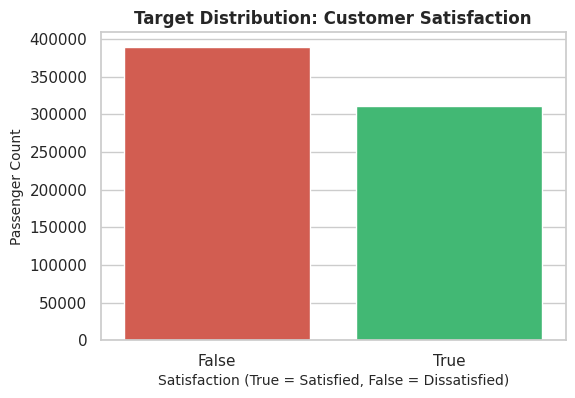

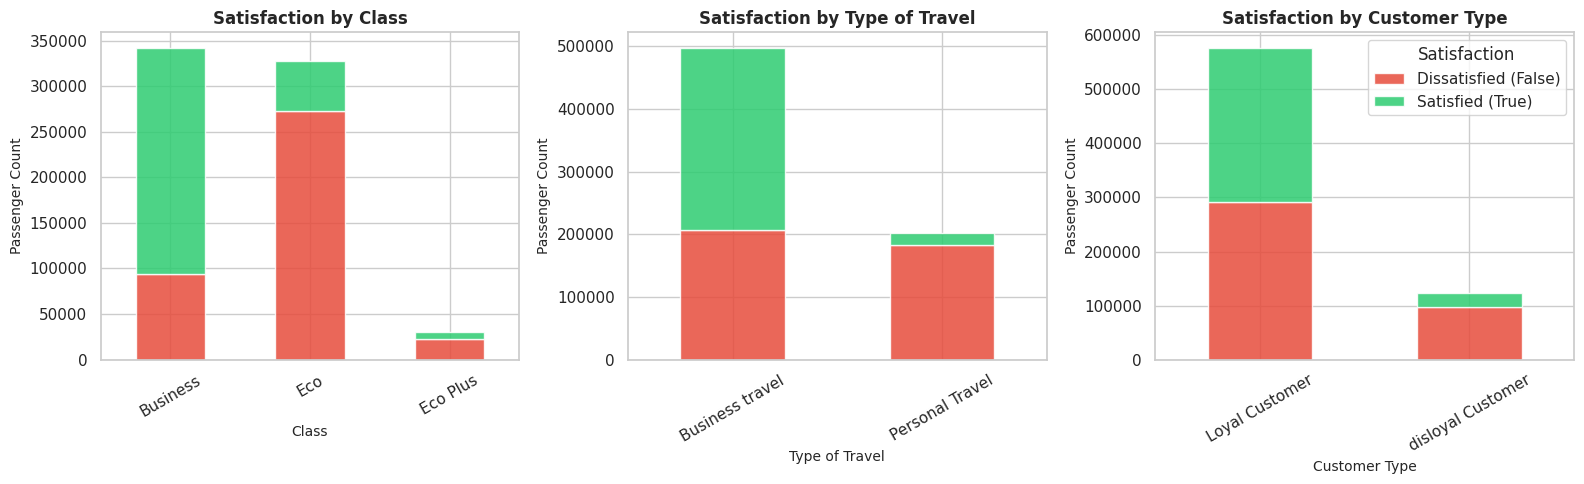

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set a clean visual style for portfolio-ready plots
sns.set_theme(style="whitegrid")

# ==========================================
# 1. Target Balance (Count Plot)
# ==========================================
plt.figure(figsize=(6, 4))
sns.countplot(data=df_train, x='satisfaction', palette=['#e74c3c', '#2ecc71'], hue='satisfaction', legend=False)
plt.title('Target Distribution: Customer Satisfaction', fontsize=12, fontweight='bold')
plt.xlabel('Satisfaction (True = Satisfied, False = Dissatisfied)', fontsize=10)
plt.ylabel('Passenger Count', fontsize=10)
plt.show()

# ==========================================
# 2. Segmented Categorical Analysis (Stacked Bar Charts)
# ==========================================
categorical_cols = ['Class', 'Type of Travel', 'Customer Type']

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, col in enumerate(categorical_cols):
    # Create a cross-tabulation of the categorical feature vs satisfaction
    ct = pd.crosstab(df_train[col], df_train['satisfaction'])

    # Plot stacked bar chart (False = Red/Dissatisfied, True = Green/Satisfied)
    ct.plot(kind='bar', stacked=True, ax=axes[i], color=['#e74c3c', '#2ecc71'], alpha=0.85)

    axes[i].set_title(f'Satisfaction by {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel(col, fontsize=10)
    axes[i].set_ylabel('Passenger Count', fontsize=10)
    axes[i].tick_params(axis='x', rotation=30)

    # Clean up legends: show legend only on the last plot, remove others
    if i == 2:
        axes[i].legend(['Dissatisfied (False)', 'Satisfied (True)'], title='Satisfaction', loc='upper right')
    else:
        if axes[i].get_legend() is not None:
            axes[i].get_legend().remove()

plt.tight_layout()
plt.show()

# Exploratory Data Analysis: Passenger Satisfaction Highlights

This section provides a detailed breakdown of passenger satisfaction metrics across three core categorical dimensions: **Travel Class**, **Type of Travel**, and **Customer Type**.

---

## 1. Satisfaction by Travel Class

* **Business Class (Highest Satisfaction Rate)**  
  Business class passengers represent the highest satisfaction proportion, with roughly **250,000 satisfied passengers** compared to under **100,000 dissatisfied passengers**.
  
* **Eco / Economy Class (Highest Disproportion of Dissatisfaction)**  
  Eco class accounts for the largest overall volume of dissatisfied customers, with over **270,000 dissatisfied passengers** and only around **55,000 satisfied passengers**.
  
* **Eco Plus Class (Smallest Segment)**  
  Eco Plus represents the smallest overall volume (30,000 passengers total), with dissatisfied passengers (20,000) outnumbering satisfied ones (10,000).

---

## 2. Satisfaction by Type of Travel

* **Business Travel**  
  Accounts for the vast majority of overall passenger volume (500,000). The majority of business travelers report positive experiences, with nearly **300,000 satisfied passengers** versus **200,000 dissatisfied passengers**.
  
* **Personal Travel**  
  Represents a major area of operational friction. Out of approximately 200,000 personal travelers, over **180,000 are dissatisfied**, while only a small fraction (20,000) are satisfied.

---

## 3. Satisfaction by Customer Type

* **Loyal Customers**  
  Form the core customer base with nearly **600,000 total passengers**. The breakdown is almost evenly split, with approximately **280,000 satisfied passengers** and **290,000 dissatisfied passengers**.
  
* **Disloyal Customers**  
  Make up roughly 120,000 total passengers, with the vast majority (**~100,000 passengers**) reporting dissatisfaction.

---

## Key Takeaways & Strategic Insights

1. **Primary Drivers of High Satisfaction**: Flying in **Business Class** and traveling for **Business** are the strongest predictors of overall passenger satisfaction.
2. **Primary Drivers of Dissatisfaction**: Flying **Eco Class**, traveling for **Personal reasons**, or being a **Disloyal customer** strongly correlate with low satisfaction levels.
3. **Core Loyalty Risk**: Nearly half of all **Loyal Customers** are dissatisfied (~290,000), highlighting an urgent operational need to improve service quality in Economy cabins to protect long-term customer retention.

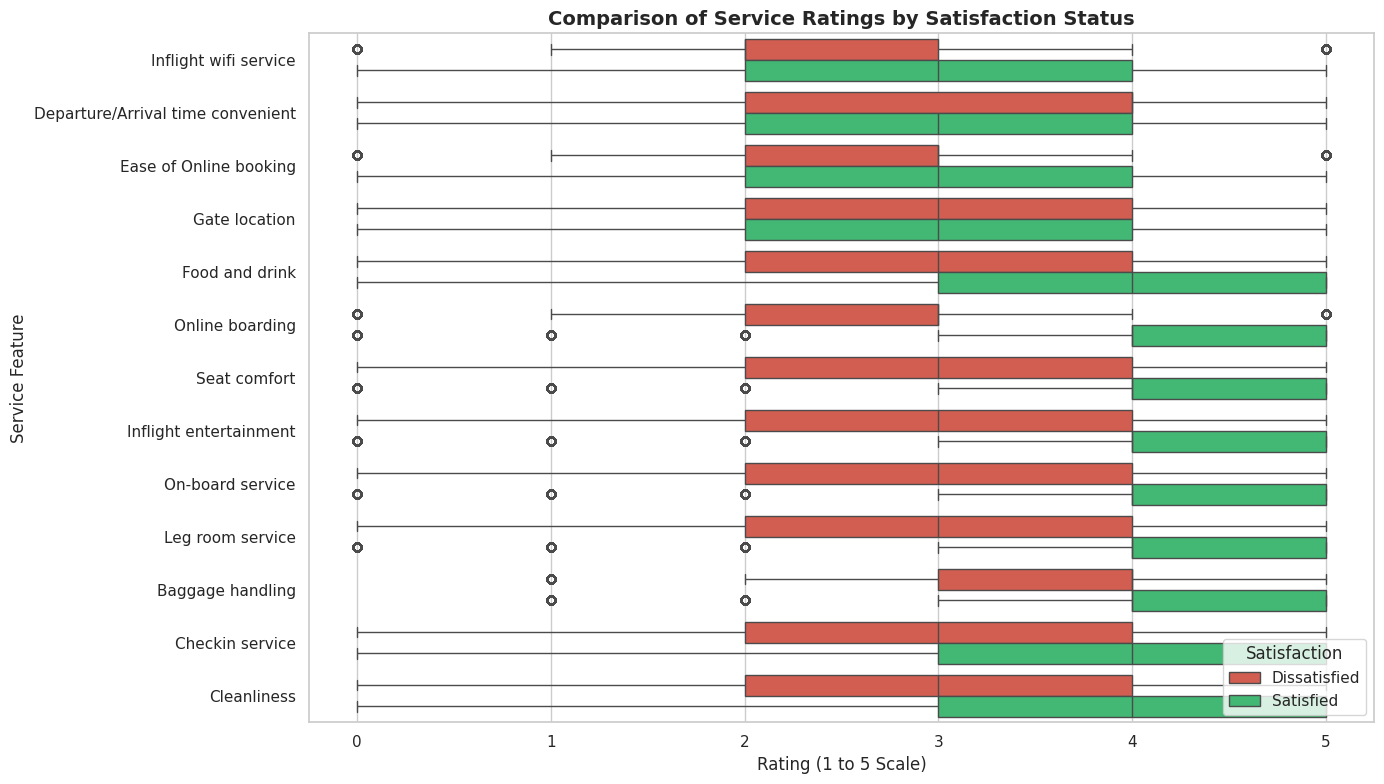

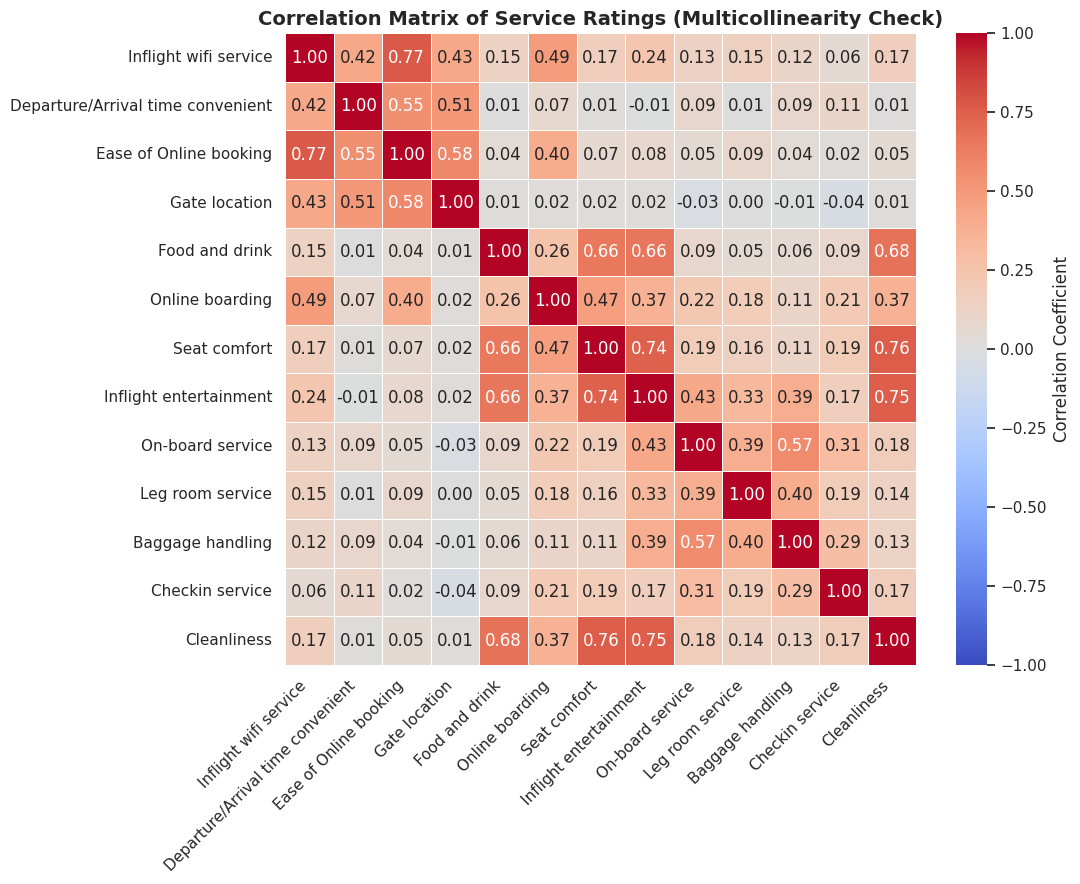

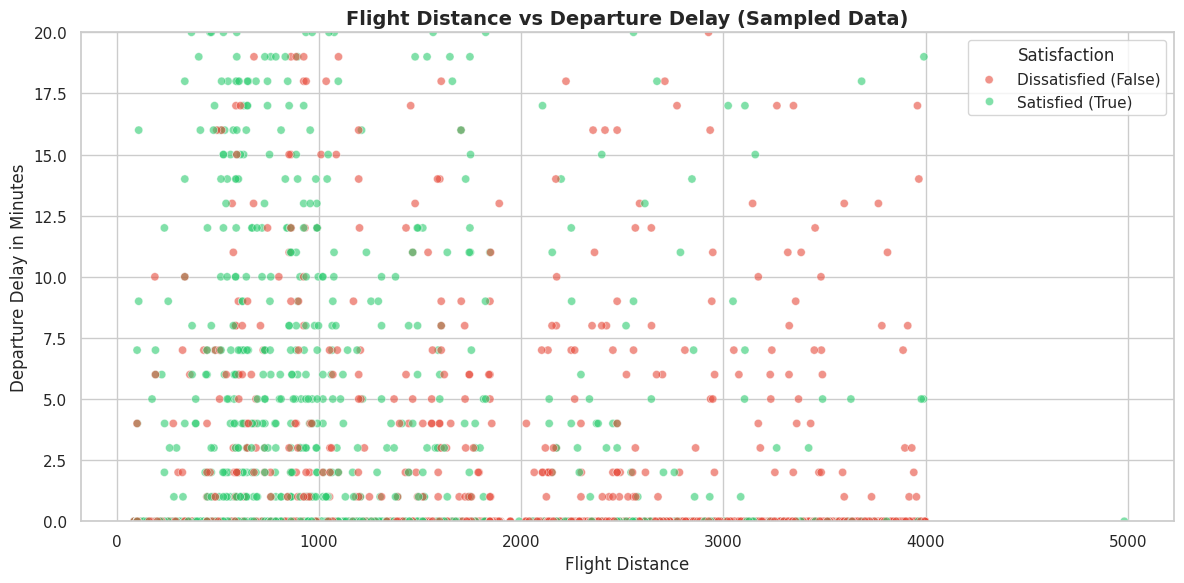

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure clean styling
sns.set_theme(style="whitegrid")

# Define the 13 ordinal service rating columns
service_cols = [
    'Inflight wifi service', 'Departure/Arrival time convenient',
    'Ease of Online booking', 'Gate location', 'Food and drink',
    'Online boarding', 'Seat comfort', 'Inflight entertainment',
    'On-board service', 'Leg room service', 'Baggage handling',
    'Checkin service', 'Cleanliness'
]

# ==========================================
# 1. Rating Comparison (Boxplots)
# ==========================================
# Melt the DataFrame from wide to long format for clean categorical grouping
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

service_cols = [
    'Inflight wifi service', 'Departure/Arrival time convenient',
    'Ease of Online booking', 'Gate location', 'Food and drink',
    'Online boarding', 'Seat comfort', 'Inflight entertainment',
    'On-board service', 'Leg room service', 'Baggage handling',
    'Checkin service', 'Cleanliness'
]

# Melt the DataFrame using the new label column
df_melted = pd.melt(
    df_train.assign(Satisfaction_Status=df_train['satisfaction'].map({True: 'Satisfied', False: 'Dissatisfied'})),
    id_vars=['Satisfaction_Status'],
    value_vars=service_cols,
    var_name='Service Feature',
    value_name='Rating'
)

# Plot with an explicit dictionary palette (guarantees correct colors)
plt.figure(figsize=(14, 8))
sns.boxplot(
    data=df_melted,
    x='Rating',
    y='Service Feature',
    hue='Satisfaction_Status',
    palette={
        'Dissatisfied': '#e74c3c',  # Red
        'Satisfied': '#2ecc71'     # Green
    },
    orient='h'
)

plt.title('Comparison of Service Ratings by Satisfaction Status', fontsize=14, fontweight='bold')
plt.xlabel('Rating (1 to 5 Scale)', fontsize=12)
plt.ylabel('Service Feature', fontsize=12)

# Let Seaborn handle the legend natively using the dictionary keys
plt.legend(title='Satisfaction', loc='lower right')
plt.tight_layout()
plt.show()

# ==========================================
# 2. Feature Correlation Matrix (Heatmap)
# ==========================================
plt.figure(figsize=(11, 9))
corr_matrix = df_train[service_cols].corr()

# Draw the heatmap
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    cbar_kws={'label': 'Correlation Coefficient'}
)
plt.title('Correlation Matrix of Service Ratings (Multicollinearity Check)', fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# ==========================================
# 3. Delay Impact (Scatter Plot with Sub-sampling)
# ==========================================
# Sub-sample 10,000 rows for smooth rendering given the large dataset size (~700k rows)
df_sample = df_train.sample(n=min(10000, len(df_train)), random_state=42)

plt.figure(figsize=(12, 6))
sns.scatterplot(
    data=df_sample,
    x='Flight Distance',
    y='Departure Delay in Minutes',
    hue='satisfaction',
    palette=['#2ecc71','#e74c3c'],
    alpha=0.6,
    s=35
)
plt.title('Flight Distance vs Departure Delay (Sampled Data)', fontsize=14, fontweight='bold')
plt.xlabel('Flight Distance', fontsize=12)
plt.ylabel('Departure Delay in Minutes', fontsize=12)

# Focus the view on the main cluster (ignoring extreme outlier tails for visualization clarity)
plt.ylim(0, df_sample['Departure Delay in Minutes'].quantile(0.98))

plt.legend(title='Satisfaction', labels=['Dissatisfied (False)', 'Satisfied (True)'])
plt.tight_layout()
plt.show()

# Comparison of Service Ratings by Satisfaction Status

This analysis evaluates passenger ratings (scale 1 to 5) across 14 service features, comparing **Dissatisfied** (Red) vs. **Satisfied** (Green) passengers to identify key satisfaction drivers and areas needing improvement.

---

## 1. High-Impact Differentiators (Core Drivers of Satisfaction)

The following service features show a clear separation between satisfied and dissatisfied passengers, indicating they are critical factors driving overall customer satisfaction:

* **Online Boarding**  
  * **Satisfied**: Ratings are heavily concentrated in the upper tier (IQR: 4 to 5, median 4).  
  * **Dissatisfied**: Ratings are noticeably lower (IQR: 2 to 3, median 3).
  * **Insight**: Seamless online check-in and boarding is one of the strongest positive predictors of passenger satisfaction.

* **Inflight Entertainment & Seat Comfort**  
  * **Satisfied**: Both features show high median satisfaction ratings of 4 to 5 (IQR: 4 to 5).  
  * **Dissatisfied**: Ratings peak at median 3 (IQR: 2 to 4).  
  * **Insight**: Onboard comfort and leisure amenities directly correlate with positive passenger experiences.

* **On-board Service, Leg Room Service, Baggage Handling, & Cleanliness**  
  * **Satisfied**: Show consistently higher rating distributions with medians between 4 and 5.  
  * **Dissatisfied**: Medians hover around 3 or lower.  
  * **Insight**: Cabin service quality, space, and cleanliness are essential baseline operational requirements for satisfied passengers.

---

## 2. Low-Differentiating Features (Pain Points Across Both Groups)

Certain features display nearly identical rating distributions for both satisfied and dissatisfied passengers, indicating systemic operational limitations or factors that do not strongly drive overall satisfaction:

* **Inflight Wifi Service & Ease of Online Booking**  
  * Both satisfied and dissatisfied passengers give lower-to-moderate ratings, with medians hovering around 3 (IQR: 2 to 4).  
  * **Insight**: Digital touchpoints like Wi-Fi reliability and booking usability lag across the board and fail to serve as competitive differentiators.

* **Departure/Arrival Time Convenient & Gate Location**  
  * Show almost identical box plot distributions across both groups (IQR: 2 to 4, median 3).  
  * **Insight**: Flight scheduling convenience and airport gate assignments impact all travelers equally regardless of their ultimate satisfaction status.

* **Food and Drink & Checkin Service**  
  * Show slight improvements for satisfied customers, but significant rating overlap remains between both cohorts.

---

## 3. Key Takeaways & Actionable Insights

1. **Prioritize In-Flight & Digital Experience Upgrades**: **Online boarding**, **seat comfort**, **inflight entertainment**, and **leg room** are the main service differentiators separating satisfied from dissatisfied passengers.
2. **Fix Digital & Connectivity Bottlenecks**: Inflight Wi-Fi and online booking suffer from low ratings across all customer segments, representing a prime opportunity for digital transformation.
3. **Focus Investments where Impact is Highest**: Improving gate locations or flight schedule convenience yields lower customer satisfaction returns compared to improving onboard cabin comfort and service quality.

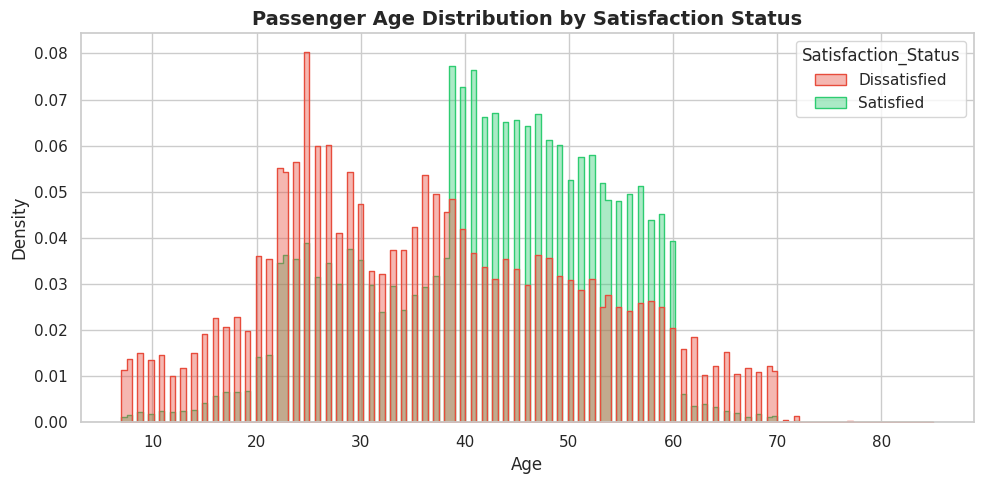

In [ ]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 5))
sns.histplot(
    data=df_train.assign(Satisfaction_Status=df_train['satisfaction'].map({True: 'Satisfied', False: 'Dissatisfied'})),
    x='Age',
    hue='Satisfaction_Status',
    element='step',
    stat='density',
    common_norm=False,
    palette={'Dissatisfied': '#e74c3c', 'Satisfied': '#2ecc71'},
    alpha=0.4
)
plt.title('Passenger Age Distribution by Satisfaction Status', fontsize=14, fontweight='bold')
plt.xlabel('Age', fontsize=12)
plt.ylabel('Density', fontsize=12)
plt.tight_layout()
plt.show()

# Passenger Age Distribution by Satisfaction Status

This analysis examines the density distribution of passenger age across **Dissatisfied** (Red) and **Satisfied** (Green) passenger cohorts to understand demographic trends and age-related satisfaction patterns.

---

## 1. Key Demographic Findings by Age Group

* **Young Passengers (Ages 7–38)**  
  * **Pattern**: Dissatisfaction consistently outweighs satisfaction across almost this entire age range.
  * **Peaks**: A strong spike in dissatisfaction occurs around ages **22 to 28**, with a major peak near age **25** (density ~0.08 for dissatisfied vs. ~0.04 for satisfied).
  * **Insight**: Younger travelers, likely flying Economy or for personal travel, report significantly higher rates of dissatisfaction.

* **Middle-Aged Passengers (Ages 39–60)**  
  * **Pattern**: Satisfaction strongly dominates dissatisfaction in this demographic cohort.
  * **Peaks**: The highest concentration of satisfied passengers occurs between ages **39 and 50**, peaking around ages **39–41** (density ~0.075 to 0.08 for satisfied vs. ~0.04 for dissatisfied).
  * **Insight**: Passengers in their peak career years—who are more likely to fly Business Class or for business travel—report the highest satisfaction levels.

* **Older Passengers (Ages 61+)**  
  * **Pattern**: Overall passenger density declines sharply after age 60, but dissatisfaction again outpaces satisfaction.
  * **Insight**: Seniors and elderly travelers experience higher dissatisfaction rates, possibly due to airport accessibility, boarding friction, or physical comfort issues.

---

## 2. Key Takeaways & Strategic Insights

1. **Targeted Experience Improvements for Young Adults (20–30)**: Young adults represent the largest dissatisfied demographic peak. Tailoring digital services, value-focused perks, and budget-friendly cabin experiences can help convert this segment into loyal, satisfied customers.
2. **Leverage the Core Business Demographic (39–60)**: Middle-aged travelers drive the vast majority of positive feedback. Maintaining premium service standards in Business Class is essential to preserving this high-satisfaction revenue core.
3. **Address Senior Traveler Needs (60+)**: Although a smaller segment overall, passengers over 60 show a high ratio of dissatisfaction to satisfaction, signaling a need for better assistance, streamlined boarding, and enhanced seating comfort.

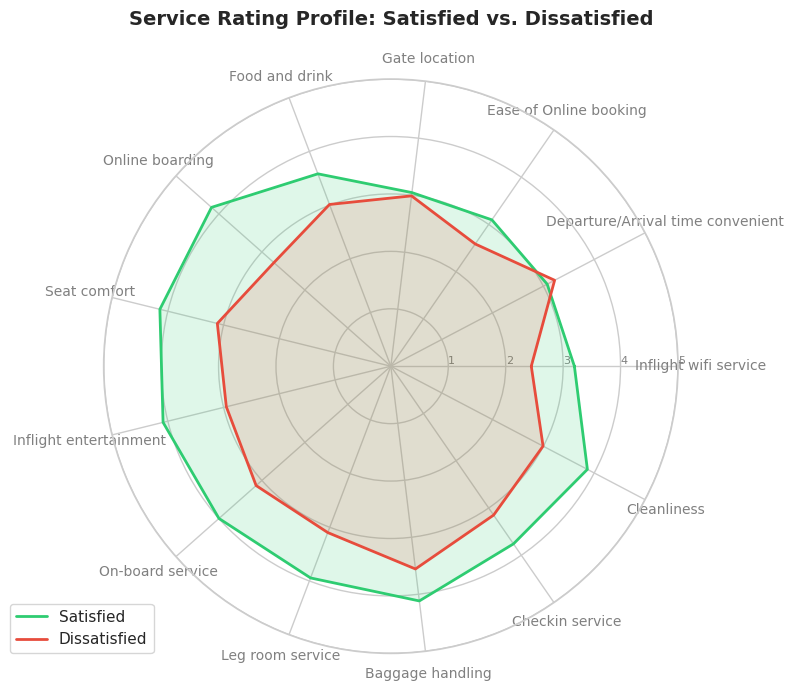

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

service_cols = [
    'Inflight wifi service', 'Departure/Arrival time convenient',
    'Ease of Online booking', 'Gate location', 'Food and drink',
    'Online boarding', 'Seat comfort', 'Inflight entertainment',
    'On-board service', 'Leg room service', 'Baggage handling',
    'Checkin service', 'Cleanliness'
]

# Calculate mean ratings for satisfied vs dissatisfied groups
df_temp = df_train.assign(Satisfaction_Status=df_train['satisfaction'].map({True: 'Satisfied', False: 'Dissatisfied'}))
radar_df = df_temp.groupby('Satisfaction_Status')[service_cols].mean().T
radar_df.columns = ['Dissatisfied', 'Satisfied']

# Number of variables
categories = service_cols
N = len(categories)

# Compute angle for each axis
angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]  # Close the loop

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

# Draw lines and fill for Satisfied
values_sat = radar_df['Satisfied'].values.tolist()
values_sat += values_sat[:1]
ax.plot(angles, values_sat, linewidth=2, linestyle='solid', label='Satisfied', color='#2ecc71')
ax.fill(angles, values_sat, '#2ecc71', alpha=0.15)

# Draw lines and fill for Dissatisfied
values_dissat = radar_df['Dissatisfied'].values.tolist()
values_dissat += values_dissat[:1]
ax.plot(angles, values_dissat, linewidth=2, linestyle='solid', label='Dissatisfied', color='#e74c3c')
ax.fill(angles, values_dissat, '#e74c3c', alpha=0.15)

# Fix axis labels and layout
plt.xticks(angles[:-1], categories, color='grey', size=10)
ax.set_rlabel_position(0)
plt.yticks([1, 2, 3, 4, 5], ["1", "2", "3", "4", "5"], color="grey", size=8)
plt.ylim(0, 5)

plt.title('Service Rating Profile: Satisfied vs. Dissatisfied', fontsize=14, fontweight='bold', y=1.08)
plt.legend(loc='upper right', bbox_to_anchor=(0.1, 0.1))
plt.tight_layout()
plt.show()

# Service Rating Profile: Satisfied vs. Dissatisfied

This radar chart provides a multi-dimensional comparison of average customer ratings across 14 service features, contrasting **Satisfied** (Green) and **Dissatisfied** (Red) passenger profiles to highlight operational strengths, performance gaps, and common pain points.

---

## 1. Largest Service Performance Gaps (Key Differentiators)

The widest gaps between the green and red radar profiles highlight the features that contribute most significantly to passenger satisfaction:

* **Inflight Entertainment & Seat Comfort**  
  * **Satisfied Profile**: Scores very high (~4.0+ out of 5).  
  * **Dissatisfied Profile**: Scores considerably lower (~2.5 to 3.0).  
  * **Insight**: Onboard comfort and leisure options are critical drivers that separate delighted flyers from dissatisfied ones.

* **Online Boarding**  
  * **Satisfied Profile**: Shows a strong, extended peak (~4.0+).  
  * **Dissatisfied Profile**: Drops to ~2.8.  
  * **Insight**: Digital check-in and boarding efficiency significantly impact the overall passenger journey experience.

* **On-board Service, Leg Room Service, & Cleanliness**  
  * **Satisfied Profile**: Maintains consistently high ratings (~3.8 to 4.0).  
  * **Dissatisfied Profile**: Lags significantly behind (~2.8 to 3.0).  
  * **Insight**: Physical space and staff service quality directly elevate customer satisfaction levels.

---

## 2. Overlapping & Low-Performing Features (Systemic Issues)

Where the red and green profiles overlap or remain close to the center, the service features fail to create a strong competitive advantage:

* **Inflight Wifi Service & Ease of Online Booking**  
  * Both cohorts score low-to-moderate ratings (~2.5 to 3.0).  
  * **Insight**: Digital connectivity and online booking usability represent shared pain points across all passenger segments.

* **Gate Location & Departure/Arrival Time Convenience**  
  * The green and red profiles nearly align (~3.0 to 3.2).  
  * **Insight**: Scheduling and gate proximity affect both satisfied and dissatisfied travelers almost equally.

---

## 3. Key Takeaways & Strategic Recommendations

1. **Focus Enhancement Efforts on Core Differentiators**: Upgrading **Seat Comfort**, **Inflight Entertainment**, **Online Boarding**, and **Leg Room** will yield the highest ROI for driving passenger satisfaction.
2. **Modernize Digital Infrastructure**: Inflight Wi-Fi and online booking interfaces receive subpar scores across both groups, representing an urgent opportunity for modernizing digital touchpoints.
3. **Maintain High Standards for Cabin Service**: High ratings in **Cleanliness**, **On-board Service**, and **Baggage Handling** form the baseline foundation required to keep satisfied customers delighted.

In [6]:
# Convert boolean satisfaction to binary integer (True -> 1, False -> 0)
df_train['satisfaction'] = df_train['satisfaction'].astype(int)

# Verify the conversion and class balance
print(df_train['satisfaction'].value_counts(normalize=True))

satisfaction
0    0.556427
1    0.443573
Name: proportion, dtype: float64


In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# 1. Handle missing values in Arrival Delay
df_train['Arrival Delay in Minutes'] = df_train['Arrival Delay in Minutes'].fillna(df_train['Arrival Delay in Minutes'].median())

# 2. Drop unique identifier 'id' as it adds no predictive value
if 'id' in df_train.columns:
    df_train = df_train.drop(columns=['id'])

# 3. Encode categorical features (Gender, Customer Type, Type of Travel, Class)
categorical_cols = ['Gender', 'Customer Type', 'Type of Travel', 'Class']

for col in categorical_cols:
    df_train[col] = df_train[col].astype('category')

# Separate features (X) and target (y)
X = df_train.drop(columns=['satisfaction'])
y = df_train['satisfaction']

# Train-validation split (e.g., 80% train, 20% validation)
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [8]:
!pip install optuna optuna-integration

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.2/88.2 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 10.5 MB/s eta 0:00:00


In [18]:
import optuna
import lightgbm as lgb
import numpy as np
from sklearn.metrics import roc_auc_score

# Suppress verbose Optuna logs
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    # Expanded hyperparameter search space
    params = {
        'objective': 'binary',
        'metric': 'auc',
        'boosting_type': 'gbdt',
        'learning_rate': trial.suggest_float('learning_rate', 0.005, 0.05, log=True),
        'num_leaves': trial.suggest_int('num_leaves', 31, 255),
        'max_depth': trial.suggest_int('max_depth', -1, 15),
        'min_child_samples': trial.suggest_int('min_child_samples', 10, 150),
        'min_child_weight': trial.suggest_float('min_child_weight', 1e-3, 10.0, log=True),
        'feature_fraction': trial.suggest_float('feature_fraction', 0.5, 1.0),
        'bagging_fraction': trial.suggest_float('bagging_fraction', 0.5, 1.0),
        'bagging_freq': trial.suggest_int('bagging_freq', 1, 7),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-8, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-8, 10.0, log=True),
        'extra_trees': trial.suggest_categorical('extra_trees', [True, False]),
        'random_state': 42,
        'verbose': -1,
        'n_jobs': -1
    }

    # If you have categorical features, specify them here:
    # cv_data = lgb.Dataset(X_train, label=y_train, categorical_feature=['col1', 'col2'])
    cv_data = lgb.Dataset(X_train, label=y_train)

    # Increased early stopping patience to match lower learning rate
    callbacks = [lgb.early_stopping(stopping_rounds=50, verbose=False)]

    cv_results = lgb.cv(
        params,
        cv_data,
        num_boost_round=3000,
        nfold=5,
        stratified=True,
        metrics='auc',
        callbacks=callbacks
    )

    best_auc = max(cv_results['valid auc-mean'])
    return best_auc

# Use TPE sampler for efficient Bayesian optimization
sampler = optuna.samplers.TPESampler(seed=42)
print("Starting Optimized Optuna Hyperparameter...")
study = optuna.create_study(direction='maximize', sampler=sampler)
study.optimize(objective, n_trials=40, show_progress_bar=True)

print("\nOptimization Complete!")
print(f"-> Best Cross-Validation ROC AUC: {study.best_value:.5f}")
print("-> Best Hyperparameters:")
for key, value in study.best_params.items():
    print(f"   {key}: {value}")

Starting Optimized Optuna Hyperparameter...


  0%|          | 0/40 [00:00<?, ?it/s]


Optimization Complete!
-> Best Cross-Validation ROC AUC: 0.95914
-> Best Hyperparameters:
   learning_rate: 0.007100631102320946
   num_leaves: 105
   max_depth: 14
   min_child_samples: 127
   min_child_weight: 0.3103641958132187
   feature_fraction: 0.8586079810789649
   bagging_fraction: 0.6953133543249677
   bagging_freq: 1
   reg_alpha: 0.04521219577938434
   reg_lambda: 1.8337641374927986e-06
   extra_trees: False


In [19]:
import joblib

import numpy as np
from sklearn.metrics import roc_auc_score, classification_report

# Suppress verbose Optuna logs
optuna.logging.set_verbosity(optuna.logging.WARNING)
# Extract best parameters and add required static parameters (including L4 GPU configuration)
best_params = study.best_params.copy()
best_params.update({
    'objective': 'binary',
    'metric': 'auc',
    'boosting_type': 'gbdt',
    #'device': 'cuda',  # Enables native CUDA acceleration on the L4 GPU
    'random_state': 42,
    'verbose': -1,
    'n_jobs': -1
})

# Run a final cross-validation round with best parameters to find optimal number of boosting rounds
cv_data_final = lgb.Dataset(X_train, label=y_train)
cv_results_final = lgb.cv(
    best_params,
    cv_data_final,
    num_boost_round=1500,
    nfold=5,
    stratified=True,
    metrics='auc',
    callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)]
)

optimal_boost_rounds = len(cv_results_final['valid auc-mean'])
print(f"Optimal number of boosting rounds: {optimal_boost_rounds}")

# Train the final model on the full training set using optimal rounds
train_data_final = lgb.Dataset(X_train, label=y_train)
val_data_final = lgb.Dataset(X_val, label=y_val, reference=train_data_final)

optuna_model = lgb.train(
    best_params,
    train_data_final,
    num_boost_round=optimal_boost_rounds,
    valid_sets=[val_data_final],
    callbacks=[lgb.log_evaluation(period=50)]
)

# Evaluate on the validation set
y_pred_proba_optuna = optuna_model.predict(X_val)
final_roc_auc = roc_auc_score(y_val, y_pred_proba_optuna)
print(f"\nFinal Validation ROC AUC Score (Optuna Optimized Model): {final_roc_auc:.5f}")

# Optional: Classification report
y_pred_optuna = (y_pred_proba_optuna >= 0.5).astype(int)
print("\nClassification Report:")
print(classification_report(y_val, y_pred_optuna))

# ==========================================
# SAVE THE MODEL TO YOUR JUPYTER ENVIRONMENT
# ==========================================


# Method 2: Joblib save (Alternative if you prefer standard python serialization)
joblib_filename = 'lgbm_best_model_2.pkl'
joblib.dump(optuna_model, joblib_filename)
print(f"-> Model successfully saved via joblib as: {joblib_filename}")

Optimal number of boosting rounds: 1499
[50]	valid_0's auc: 0.953329
[100]	valid_0's auc: 0.953655
[150]	valid_0's auc: 0.953955
[200]	valid_0's auc: 0.95436
[250]	valid_0's auc: 0.954754
[300]	valid_0's auc: 0.954989
[350]	valid_0's auc: 0.95529
[400]	valid_0's auc: 0.955556
[450]	valid_0's auc: 0.955814
[500]	valid_0's auc: 0.956094
[550]	valid_0's auc: 0.956346
[600]	valid_0's auc: 0.956611
[650]	valid_0's auc: 0.956853
[700]	valid_0's auc: 0.957052
[750]	valid_0's auc: 0.957228
[800]	valid_0's auc: 0.957384
[850]	valid_0's auc: 0.957512
[900]	valid_0's auc: 0.957622
[950]	valid_0's auc: 0.957693
[1000]	valid_0's auc: 0.957754
[1050]	valid_0's auc: 0.957809
[1100]	valid_0's auc: 0.957864
[1150]	valid_0's auc: 0.957899
[1200]	valid_0's auc: 0.957924
[1250]	valid_0's auc: 0.957954
[1300]	valid_0's auc: 0.957988
[1350]	valid_0's auc: 0.958005
[1400]	valid_0's auc: 0.958008
[1450]	valid_0's auc: 0.958026

Final Validation ROC AUC Score (Optuna Optimized Model): 0.95804

Classification R

In [10]:
import joblib

import numpy as np
from sklearn.metrics import roc_auc_score, classification_report

# Suppress verbose Optuna logs
optuna.logging.set_verbosity(optuna.logging.WARNING)
# Extract best parameters and add required static parameters (including L4 GPU configuration)
best_params = study.best_params.copy()
best_params.update({
    'objective': 'binary',
    'metric': 'auc',
    'boosting_type': 'gbdt',
    #'device': 'cuda',  # Enables native CUDA acceleration on the L4 GPU
    'random_state': 42,
    'verbose': -1,
    'n_jobs': -1
})

# Run a final cross-validation round with best parameters to find optimal number of boosting rounds
cv_data_final = lgb.Dataset(X_train, label=y_train)
cv_results_final = lgb.cv(
    best_params,
    cv_data_final,
    num_boost_round=1500,
    nfold=5,
    stratified=True,
    metrics='auc',
    callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)]
)

optimal_boost_rounds = len(cv_results_final['valid auc-mean'])
print(f"Optimal number of boosting rounds: {optimal_boost_rounds}")

# Train the final model on the full training set using optimal rounds
train_data_final = lgb.Dataset(X_train, label=y_train)
val_data_final = lgb.Dataset(X_val, label=y_val, reference=train_data_final)

optuna_model = lgb.train(
    best_params,
    train_data_final,
    num_boost_round=optimal_boost_rounds,
    valid_sets=[val_data_final],
    callbacks=[lgb.log_evaluation(period=50)]
)

# Evaluate on the validation set
y_pred_proba_optuna = optuna_model.predict(X_val)
final_roc_auc = roc_auc_score(y_val, y_pred_proba_optuna)
print(f"\nFinal Validation ROC AUC Score (Optuna Optimized Model): {final_roc_auc:.5f}")

# Optional: Classification report
y_pred_optuna = (y_pred_proba_optuna >= 0.5).astype(int)
print("\nClassification Report:")
print(classification_report(y_val, y_pred_optuna))

# ==========================================
# SAVE THE MODEL TO YOUR JUPYTER ENVIRONMENT
# ==========================================


# Method 2: Joblib save (Alternative if you prefer standard python serialization)
joblib_filename = 'lgbm_best_model_3.pkl'
joblib.dump(optuna_model, joblib_filename)
print(f"-> Model successfully saved via joblib as: {joblib_filename}")

Optimal number of boosting rounds: 1471
[50]	valid_0's auc: 0.954476
[100]	valid_0's auc: 0.95487
[150]	valid_0's auc: 0.95538
[200]	valid_0's auc: 0.955865
[250]	valid_0's auc: 0.956298
[300]	valid_0's auc: 0.956711
[350]	valid_0's auc: 0.95704
[400]	valid_0's auc: 0.9573
[450]	valid_0's auc: 0.957545
[500]	valid_0's auc: 0.957694
[550]	valid_0's auc: 0.957818
[600]	valid_0's auc: 0.957874
[650]	valid_0's auc: 0.957929
[700]	valid_0's auc: 0.95797
[750]	valid_0's auc: 0.957982
[800]	valid_0's auc: 0.958026
[850]	valid_0's auc: 0.958043
[900]	valid_0's auc: 0.958054
[950]	valid_0's auc: 0.958066
[1000]	valid_0's auc: 0.958075
[1050]	valid_0's auc: 0.958084
[1100]	valid_0's auc: 0.958094
[1150]	valid_0's auc: 0.958103
[1200]	valid_0's auc: 0.958113
[1250]	valid_0's auc: 0.958125
[1300]	valid_0's auc: 0.958134
[1350]	valid_0's auc: 0.958135
[1400]	valid_0's auc: 0.958135
[1450]	valid_0's auc: 0.958135

Final Validation ROC AUC Score (Optuna Optimized Model): 0.95814

Classification Repor

In [11]:
df_test= pd.read_csv('/content/airline_data/test.csv')
df_test.head()

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class
0,699635,25,1197,4,4,4,2,3,4,3,...,5,2,1,3,0,0.0,Female,disloyal Customer,Business travel,Eco
1,699636,36,829,5,5,5,5,5,4,5,...,2,4,3,5,0,0.0,Male,Loyal Customer,Business travel,Eco
2,699637,45,472,4,5,5,5,4,4,4,...,3,1,3,4,0,0.0,Male,Loyal Customer,Business travel,Eco
3,699638,45,762,2,2,2,5,3,2,3,...,4,4,4,3,0,0.0,Female,disloyal Customer,Business travel,Business
4,699639,34,594,1,2,1,1,2,1,2,...,4,2,1,2,0,0.0,Male,Loyal Customer,Personal Travel,Eco Plus


In [12]:
df_test.isna().sum()

,0
id,0
Age,0
Flight Distance,0
Inflight wifi service,0
Departure/Arrival time convenient,0
Ease of Online booking,0
Gate location,0
Food and drink,0
Online boarding,0
Seat comfort,0


In [13]:
df_test['Arrival Delay in Minutes'] = df_test['Arrival Delay in Minutes'].fillna(0)
df_test.isna().sum()

,0
id,0
Age,0
Flight Distance,0
Inflight wifi service,0
Departure/Arrival time convenient,0
Ease of Online booking,0
Gate location,0
Food and drink,0
Online boarding,0
Seat comfort,0


In [14]:
df_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299844 entries, 0 to 299843
Data columns (total 22 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   id                                 299844 non-null  int64  
 1   Age                                299844 non-null  int64  
 2   Flight Distance                    299844 non-null  int64  
 3   Inflight wifi service              299844 non-null  int64  
 4   Departure/Arrival time convenient  299844 non-null  int64  
 5   Ease of Online booking             299844 non-null  int64  
 6   Gate location                      299844 non-null  int64  
 7   Food and drink                     299844 non-null  int64  
 8   Online boarding                    299844 non-null  int64  
 9   Seat comfort                       299844 non-null  int64  
 10  Inflight entertainment             299844 non-null  int64  
 11  On-board service                   2998

In [15]:
import pandas as pd


# Ensure categorical features are set to 'category' dtype (required for LightGBM)
categorical_cols = ['Gender', 'Customer Type', 'Type of Travel', 'Class']
for col in categorical_cols:
    if col in df_test.columns:
        df_test[col] = df_test[col].astype('category')

# 2. Separate the 'id' column for the submission file and prepare features (X_test)
cols_to_drop = ['id', 'satisfaction'] if 'satisfaction' in df_test.columns else ['id']
X_test = df_test.drop(columns=[col for col in cols_to_drop if col in df_test.columns])

# 3. Generate probability predictions using your GPU-trained Optuna model
y_pred_proba = optuna_model.predict(X_test, num_iteration=optuna_model.best_iteration)

# 4. Create the submission DataFrame with 'id' and 'satisfaction'
submission = pd.DataFrame({
    'id': df_test['id'],
    'satisfaction': y_pred_proba
})

# 5. Save the submission DataFrame to a CSV file (without row index numbers)
submission.to_csv('submission_optuna_lgb_3.csv', index=False)

# Display the first few rows to verify the output format
print("Submission file successfully created! First 5 rows:")
print(submission.head())

Submission file successfully created! First 5 rows:
       id  satisfaction
0  699635      0.306194
1  699636      0.882702
2  699637      0.911650
3  699638      0.062840
4  699639      0.045222


In [ ]:
sub = pd.read_csv('/content/airline_data/sample_submission.csv')
sub.head()

,id,satisfaction
0,699635,0.443573
1,699636,0.443573
2,699637,0.443573
3,699638,0.443573
4,699639,0.443573
